Simplified comparison for Junqi

In [2]:
import cmocean.cm as cm
import copy
import datetime as dt
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

In [3]:
endyear = 2025
nyears = endyear - 2007 + 1

In [4]:
bathy = xr.open_dataset('/home/sallen/MEOPAR/grid/bathymetry_202108.nc')
mesh = xr.open_dataset('/home/sallen/MEOPAR/grid/mesh_mask202108.nc')

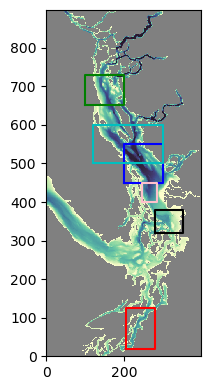

In [7]:
def plot_box(ax, corn, colour):
    ax.plot([corn[2], corn[3], corn[3], corn[2], corn[2]], 
            [corn[0], corn[0], corn[1], corn[1], corn[0]], '-', color=colour)
fig, ax = plt.subplots(1, 1, figsize=(2, 4.5))
mycmap = cm.deep
mycmap.set_bad('grey')
ax.pcolormesh(bathy['Bathymetry'], cmap=mycmap)
SoG_center = [450, 550, 200, 300]
plot_box(ax, SoG_center, 'b')
SoG_ncenter = [500, 600, 120, 300]
plot_box(ax, SoG_ncenter, 'c')
SoG_south = [320, 380, 280, 350]
plot_box(ax, SoG_south, 'k')
SoG_venus = [400, 450, 245, 285]
plot_box(ax, SoG_venus, 'pink')
SoG_north = [650, 730, 100, 200]
SS_all = [0, 898, 0, 398]
plot_box(ax, SoG_north, 'g')
PS_main = [20, 125, 205, 280]  # a bit smaller, to eliminate a piece of Hood Canal
plot_box(ax, PS_main, 'r') 

In [8]:
month_end_leap = {1: 31, 2: 29, 3:31, 4:30, 5:31, 6:30, 7:31, 8:31, 9:30, 10:31, 11:30, 12:31}
month_end =      {1: 31, 2: 28, 3:31, 4:30, 5:31, 6:30, 7:31, 8:31, 9:30, 10:31, 11:30, 12:31}

In [9]:
def calculate_mean(ds, mesh, box, idepth, var):
    if idepth[0] == idepth[1]:
        cut = ds[var][:, idepth[0], box[0]:box[1], box[2]:box[3]]
        tm = 1 - mesh.tmask[0, idepth[0], box[0]:box[1], box[2]:box[3]]
    else:
        cut = ds[var][:, idepth[0]:idepth[1], box[0]:box[1], box[2]:box[3]]
        tm = 1 - mesh.tmask[0, idepth[0]:idepth[1], box[0]:box[1], box[2]:box[3]]
    time_mean = cut.mean(axis=0)
    
    masked = np.ma.masked_array(time_mean, mask=tm)
    return masked.mean()

In [10]:
def calculate_timeseries(smonth, emonth, filestring, mesh, box, idepth, var):
    mean_temp_v = np.zeros((nyears, emonth-smonth))
    mean_temp_v_time = np.empty((nyears, emonth-smonth), dtype='datetime64[ns]')
    for iy, year in enumerate(range(2007, endyear+1, 1)):
        if year in [2008, 2012, 2016, 2020, 2024]:
            monthe = month_end_leap
        else:
            monthe = month_end
        for im, month in enumerate(range(smonth, emonth, 1)):
            last_day = monthe[month]
            mean_temp_v_time[iy, im] = dt.datetime(year, month, 1)
            ds = xr.open_dataset(filestring(year, month, last_day))
            mean_temp_v[iy, im] = calculate_mean(ds, mesh, box, idepth, var)
            ds.close()
    return mean_temp_v, mean_temp_v_time

### Upper Layer Nitrate in the Northern SoG ###

In [11]:
filestring_template = lambda year, month, last_day: f'/results2/SalishSea/month-avg.202111/SalishSeaCast_1m_biol_T_{year}{month:02d}01_{year}{month:02d}{last_day:02d}.nc'
mean_nitrate_v, mean_nitrate_v_time = calculate_timeseries(1, 12+1, filestring_template, mesh, SoG_north, (0, 10), 'nitrate')

In [12]:
# Save the files so only need to calculate once
np.savetxt('mean_nitrate_v.csv', mean_nitrate_v , comments=f'{dt.date.today}')
np.savetxt('mean_nitrate_v_time.csv', mean_nitrate_v_time , comments=f'{dt.date.today}')

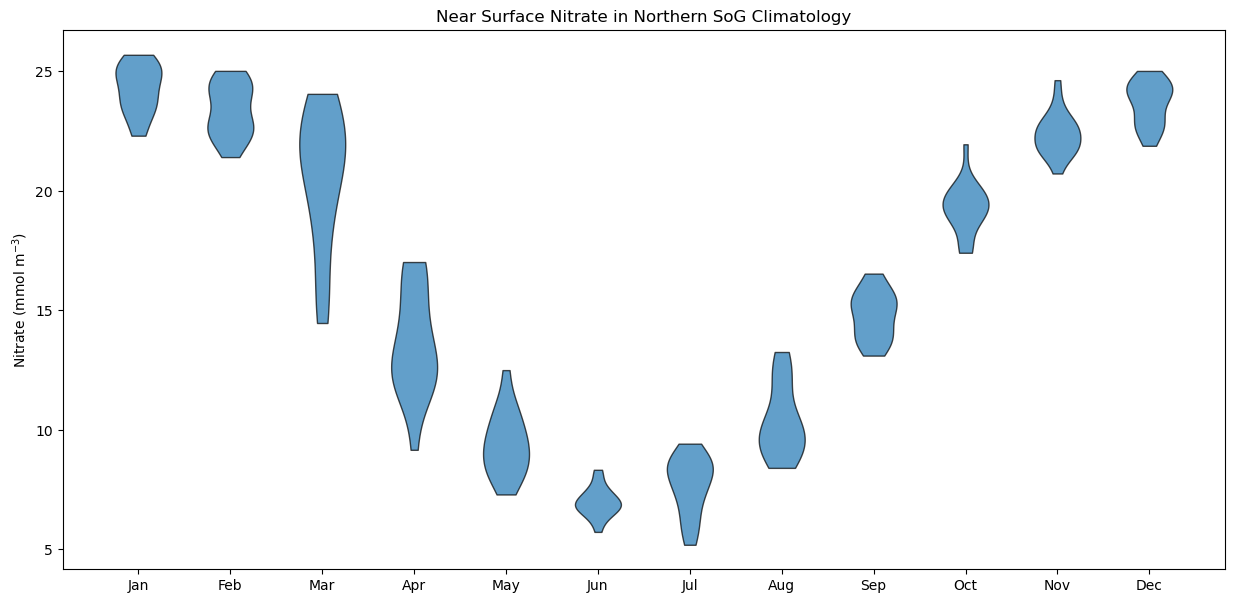

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(15, 7))
parts = ax.violinplot(mean_nitrate_v, positions=range(1, 13), showmeans=False, 
                      showmedians=False, showextrema=False)
for i, pc in enumerate(parts['bodies']):
    pc.set_edgecolor('black')    # Border color
    pc.set_alpha(0.7)            # Transparency
ax.set_title('Near Surface Nitrate in Northern SoG Climatology')
ax.set_ylabel('Nitrate (mmol m$^{-3}$)')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 
                    'Aug', 'Sep', 'Oct', 'Nov', 'Dec']);

In [17]:
filestring_template = lambda year, month: f'/data/sallen/results/MEOPAR/DownScaleAtmos/Base/monthlies/SalishSea_1m_{year}{month:02d}_{year}{month:02d}_biol_T.nc'
mean_nitrate_3h, mean_nitrate_3h_time = calculate_ts_newrun(1, 12+1, 2008, 2008+1, filestring_template, 
                                                            mesh, SoG_north, (0, 10), 'nitrate')


NameError: name 'calculate_ts_newrun' is not defined

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(15, 7))
parts = ax.violinplot(mean_nitrate_v, positions=range(1, 13), showmeans=False, showmedians=False, showextrema=False)
for i, pc in enumerate(parts['bodies']):
    pc.set_edgecolor('black')    # Border color
    pc.set_alpha(0.7)            # Transparency
iy, year = 1, 2008
ax.plot(range(1, 13), mean_nitrate_v[1], 'navy', alpha=0.5, linewidth=5, label='2008, v202111')
ax.plot(range(1, 13), mean_nitrate_3h[0], 'tab:purple', label='2008, 3 hourly')
ax.plot(range(1, 5), mean_nitrate_3h_w1hS[0], 'tab:pink', label='2008, 3h_w1hS')
ax.plot(range(1, 13), mean_nitrate_down1hS[0], 'tab:orange', label='2008, Recon_down1hs')
ax.plot(range(1, 12+1), mean_nitrate_recon[0], 'tab:red', label='2008, Recon 3 weights')
ax.set_title('Near Surface Nitrate in Northern SoG\nYear 2008 Against Climatology')
ax.set_ylabel('Nitrate (mmol m$^{-3}$)')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.legend();